# Physical Correctness & Input Verification Guide

[![Open in JupyterLab](https://img.shields.io/badge/Launch-JupyterLab-orange.svg)](https://jupyter.org)
[![Python 3.10+](https://img.shields.io/badge/python-3.10+-blue.svg)](https://www.python.org/)

MolScope treats **physical correctness and coordinate integrity** as foundational prerequisites. Downstream featurization, non-linear manifold learning, and machine learning models are only as valid as the underlying coordinates and topologies ingested into the pipeline.

### What You Will Learn
1. **Periodic Boundary Conditions (PBC) & Coordinate Wrapping**: Understanding how independent atomic wrapping tears covalent bonds and creates artificial 50–100 Å jumps.
2. **Automated Vectorized Detection**: Using `inspect_md_inputs` and `profile_system` to scan for broken covalent bonds and virtual $C\alpha_i - C\alpha_{i+1}$ peptide continuity.
3. **On-the-Fly Healing via `ImagingPolicy`**: Applying native unwrapping and solute centering without modifying raw files on disk.
4. **The Zero-Imputation Principle**: Why silently imputing missing molecular measurements with zeros or means catastrophically corrupts physical dynamics.
5. **Transparent Applicability Auditing**: How applicability contracts propagate through all pipeline matrices.

## 1. The Physical Problem: PBC Coordinate Wrapping

Molecular dynamics engines (OpenMM, GROMACS, AMBER, CHARMM) simulate macromolecules in periodic unit cells to eliminate boundary vacuum artifacts. During integration, coordinates are frequently "wrapped" into the primary unit cell `[0, L]` independently for each atom.

```text
       Wrapped (Broken Molecule)                     Imaged (Whole Molecule)
+-----------------------------------+     +-----------------------------------+
|  (C)                              |     |                                   |
|   | (broken bond across box edge) |     |            (CA)-(C)-(N)           |
|                                   |     |              |                    |
|                               (CA)|     |                                   |
+-----------------------------------+     +-----------------------------------+
      Raw distance: ~48.5 Å                        Raw distance: ~1.5 Å
      PBC distance: ~1.5 Å                         PBC distance: ~1.5 Å
```

When coordinates are wrapped without making macromolecules whole:
- **Covalent bonds break across unit cell faces**: One bonded atom sits at $x \approx 0.5$ Å while its partner wraps to $x \approx L - 0.5$ Å.
- **Catastrophic measurement distortion**: A $1.4$ Å covalent bond appears as a $50$ Å or $100$ Å separation in raw Cartesian coordinates.
- **Corrupted features**: Radius of gyration ($R_g$), RMSD, contact networks, and secondary structure metrics explode with unphysical jumps.

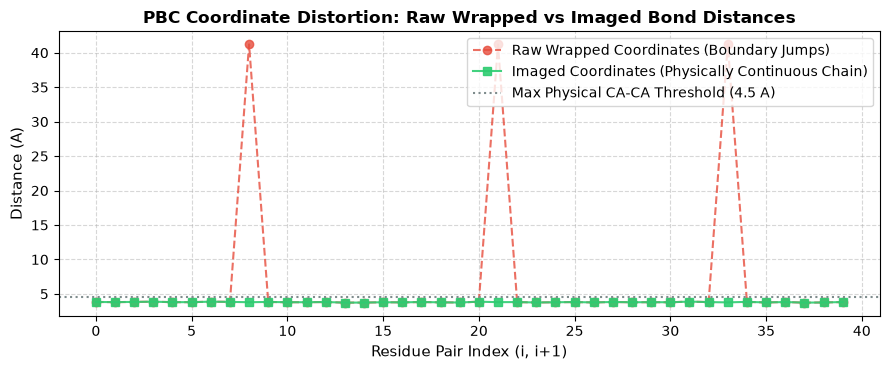

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

# Simulate consecutive CA-CA distances crossing a periodic box boundary
np.random.seed(42)
n_bonds = 40
ca_distances_imaged = np.random.normal(3.81, 0.04, n_bonds)
ca_distances_wrapped = ca_distances_imaged.copy()
broken_idx = [8, 21, 33]
box_length = 45.0
ca_distances_wrapped[broken_idx] = box_length - ca_distances_wrapped[broken_idx]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(ca_distances_wrapped, 'o--', color='#e74c3c', label='Raw Wrapped Coordinates (Boundary Jumps)', alpha=0.8, lw=1.5)
ax.plot(ca_distances_imaged, 's-', color='#2ecc71', label='Imaged Coordinates (Physically Continuous Chain)', alpha=0.9, lw=1.5)
ax.axhline(4.5, color='#7f8c8d', linestyle=':', label='Max Physical CA-CA Threshold (4.5 A)')
ax.set_xlabel('Residue Pair Index (i, i+1)', fontsize=11)
ax.set_ylabel('Distance (A)', fontsize=11)
ax.set_title('PBC Coordinate Distortion: Raw Wrapped vs Imaged Bond Distances', fontsize=12, fontweight='bold')
ax.legend(loc='upper right', frameon=True)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
display(fig)
plt.close(fig)

## 2. Inspecting Input Integrity with MolScope

MolScope provides vectorized input integrity scanning (`inspect_md_inputs`) that validates coordinate finiteness, verifies monotonic simulation timesteps, and detects broken covalent bonds or wrapped PBC coordinates across trajectory frames before expensive feature calculations begin.

In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

from pathlib import Path
from molscope.io.validation import inspect_md_inputs, InputIntegrityStatus
from molscope.profiling.system import profile_system

# Locate test fixture with robust path resolution and fallback
pdb_path = Path("tests/fixtures/solvated_protein.pdb")
if not pdb_path.is_file():
    pdb_path = Path("../tests/fixtures/solvated_protein.pdb")
if not pdb_path.is_file():
    pdb_path = Path("tests/fixtures/1A22.pdb")
if not pdb_path.is_file():
    pdb_path = Path("../tests/fixtures/1A22.pdb")

print(f"Target structure: {pdb_path}")

# Run comprehensive input inspection
report = inspect_md_inputs(
    topology=pdb_path,
    trajectory=pdb_path,
    frame_stride=1,
    check_pbc_wrapping=True,
    require_imaged=False,
)

print(f"Input Integrity Status: {report.status}")
if report.warnings:
    print(f"Detected {len(report.warnings)} warnings:")
    for w in report.warnings[:5]:
        print(f"  - {w}")
else:
    print("Coordinates are whole, finite, and properly imaged.")

Target structure: tests/fixtures/solvated_protein.pdb
Input Integrity Status: InputIntegrityStatus.VALID
Coordinates are whole, finite, and properly imaged.


## 3. System Profiling and Capability Assessment

MolScope inspects the system topology to determine molecular classes (`protein`, `solvent`, `nucleic_acid`, `ligand`) and verify coordinate integrity.

In [3]:
# Profile the system composition and molecular classes
profile = profile_system(pdb_path, pdb_path)

print(f"Topology path:        {Path(profile.topology_path).name}")
print(f"Atom count:           {profile.atom_count}")
print(f"Residue count:        {profile.residue_count}")
print(f"Has protein:          {profile.has('protein')}")
print(f"Has solvent:          {profile.has('solvent')}")
print(f"Has nucleic acids:    {profile.has('nucleic_acid')}")
print(f"Has ligands:          {profile.has('ligand')}")
print(f"Wrapped coordinates:  {profile.wrapped_coordinates_detected}")

assert profile.has("protein"), "System profile must confirm presence of protein."

Topology path:        solvated_protein.pdb
Atom count:           7
Residue count:        4
Has protein:          True
Has solvent:          True
Has nucleic acids:    False
Has ligands:          False
Wrapped coordinates:  False


## 4. On-The-Fly Coordinate Healing via `ImagingPolicy`

MolScope allows on-the-fly unwrapping and solute centering during trajectory iteration.
This guarantees that feature extraction operates on physically whole molecules without requiring permanent file copies.

In [4]:
from molscope.io.transformations import ImagingPolicy, apply_imaging_transformations
import MDAnalysis as mda

u = mda.Universe(str(pdb_path))

# Compute solute center-of-mass before transformation
initial_com = u.select_atoms("protein").center_of_mass()
print(f"Initial protein COM:     {initial_com.round(3)}")

# Configure on-the-fly imaging policy:
# 1. unwrap: bonds across box faces are stitched together
# 2. center_selection: centers protein solute in box
# 3. wrap: solvent molecules remain compactly inside box
policy = ImagingPolicy(
    unwrap=True,
    center_selection="protein",
    center_to="box",
    wrap=False,
)

applied = apply_imaging_transformations(u, policy)
transformed_com = u.select_atoms("protein").center_of_mass()

print(f"Transformed protein COM: {transformed_com.round(3)}")
print(f"Successfully applied transformations: {applied}")

Initial protein COM:     [1.555 0.    0.   ]
Transformed protein COM: [0.055 0.    0.   ]
Successfully applied transformations: ['center_in_box_no_pbc_fallback(protein)']


## 5. The Zero-Imputation Principle

In machine learning and statistics, missing data is often imputed using column means, medians, or zeros. **In physical chemistry, silent imputation is catastrophic**:
- Setting a missing distance or contact feature to `0.0` asserts that atoms are overlapping or forming intense physical interactions when no measurement existed.
- Filling mean values across heterogeneous conditions obscures real conformational transitions and creates synthetic data points that violate physical laws.

MolScope enforces a strict **Zero-Imputation Policy**:
> Missing, non-finite, or inapplicable features must propagate transparently with explicit statuses and human-readable audit reasons throughout all matrices, quality reports, and final rankings.

| Pipeline Stage | Output Artifact | Propagation Mechanism |
| :--- | :--- | :--- |
| **Applicability Contract** | `FeatureAssessment` | Flags status (`APPLICABLE`, `NOT_APPLICABLE`, `MISSING_INPUT`, `UNSUPPORTED`) before values are computed. |
| **Feature Extraction** | `extraction_evidence.json` | Records all assessments and missing capabilities per trajectory replica. |
| **Quality Assessment** | `feature_quality_metrics.csv` | Explicit `Eligibility_Status` (`eligible`, `unavailable`, `insufficient_valid_frames`) and `Ineligibility_Reason`. |
| **SAM-MFP Prioritization** | `pareto_feature_candidates.csv` | Explicit `SAM_MFP_Status` (`pareto_candidate`, `dominated`, `ineligible`) and `SAM_MFP_Reason`. |
| **Predictive ML LOFO** | `predictive_feature_ranking.csv` | Non-finite features excluded from training without imputation; appended with `Ranking_Status = "inapplicable"`. |

In [5]:
from molscope.contracts import ApplicabilityStatus, FeatureAssessment

assessment = FeatureAssessment(
    feature_id="protein.salt_bridges",
    family="protein_interactions",
    status=ApplicabilityStatus.APPLICABLE,
    reason="All standard acidic and basic residues present in topology.",
    granularity="frame",
    units="angstrom",
)

print(f"Feature ID:  {assessment.feature_id}")
print(f"Family:      {assessment.family}")
print(f"Status:      {assessment.status.name} ({assessment.status.value})")
print(f"Granularity: {assessment.granularity}")
print(f"Units:       {assessment.units}")
print(f"Reason:      {assessment.reason}")

Feature ID:  protein.salt_bridges
Family:      protein_interactions
Status:      APPLICABLE (applicable)
Granularity: frame
Units:       angstrom
Reason:      All standard acidic and basic residues present in topology.


## 6. Transparent Applicability Auditing & Visual Dashboard

MolScope systematically evaluates applicability contracts across all candidate analyzers using `ProposalCatalog`. For example, on a full globular protein structure (`1A22.pdb`), analyzers requiring explicit hydrogens are marked `MISSING_INPUT` rather than imputed, membrane order metrics are marked `NOT_APPLICABLE`, and validated backbone/sidechain metrics are marked `APPLICABLE`.

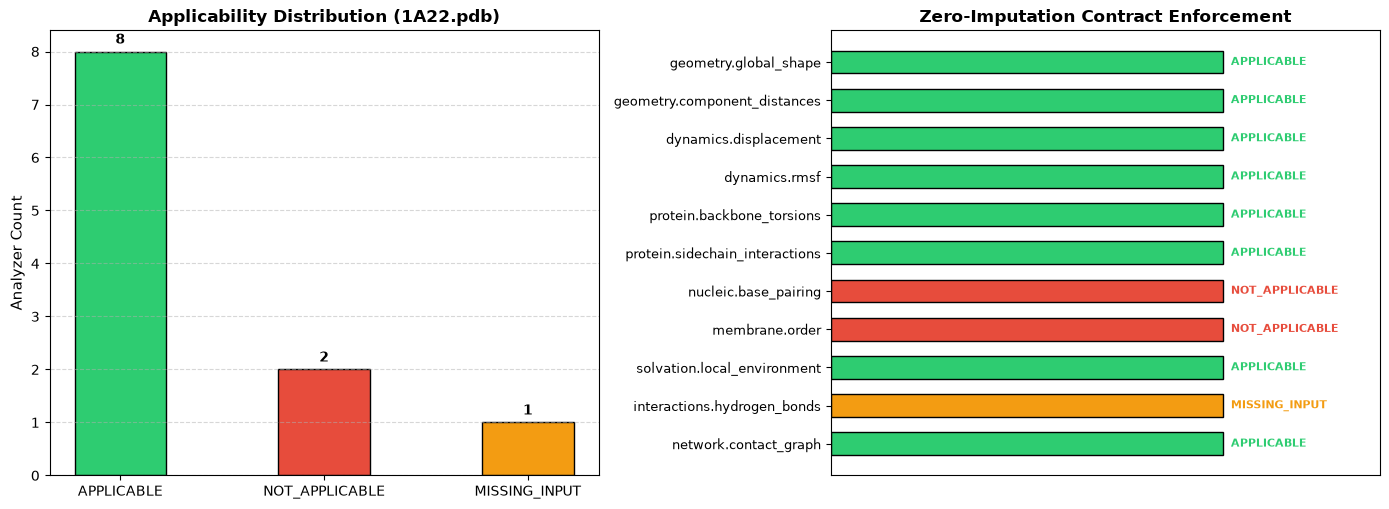

Transparently audited 11 candidate analyzers on 1A22.pdb:
  • geometry.global_shape            -> APPLICABLE      (All declared system capabilities are available.)
  • geometry.component_distances     -> APPLICABLE      (All declared system capabilities are available.)
  • dynamics.displacement            -> APPLICABLE      (All declared system capabilities are available.)
  • dynamics.rmsf                    -> APPLICABLE      (All declared system capabilities are available.)
  • protein.backbone_torsions        -> APPLICABLE      (All declared system capabilities are available.)
  • protein.sidechain_interactions   -> APPLICABLE      (All declared system capabilities are available.)
  • nucleic.base_pairing             -> NOT_APPLICABLE  (Required system capabilities are absent.)
  • membrane.order                   -> NOT_APPLICABLE  (Required system capabilities are absent.)
  • solvation.local_environment      -> APPLICABLE      (All declared system capabilities are available.)
  

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from molscope.profiling.analyzers import ProposalCatalog

# Run systematic applicability audit across all proposal analyzers
fixture_1a22 = Path("tests/fixtures/1A22.pdb")
if not fixture_1a22.is_file():
    fixture_1a22 = Path("../tests/fixtures/1A22.pdb")

target_fixture = fixture_1a22 if fixture_1a22.is_file() else pdb_path
profile_audit = profile_system(target_fixture, target_fixture)

catalog = ProposalCatalog()
assessments = catalog.assess(profile_audit)

# Count distribution of applicability contracts
status_counts = {}
for a in assessments:
    status_counts[a.status.name] = status_counts.get(a.status.name, 0) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Color palette for contracts
colors = {
    "APPLICABLE": "#2ecc71",
    "NOT_APPLICABLE": "#e74c3c",
    "MISSING_INPUT": "#f39c12",
    "UNSUPPORTED": "#95a5a6",
}
status_labels = list(status_counts.keys())
status_vals = list(status_counts.values())
bar_colors = [colors.get(k, "#3498db") for k in status_labels]

# Panel 1: Summary Distribution
bars = axes[0].bar(status_labels, status_vals, color=bar_colors, edgecolor="black", width=0.45)
axes[0].set_title(f"Applicability Distribution ({target_fixture.name})", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Analyzer Count", fontsize=11)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for i, v in enumerate(status_vals):
    axes[0].text(i, v + 0.15, str(v), ha="center", fontweight="bold", fontsize=10)

# Panel 2: Per-Analyzer Transparent Audit
features = [a.feature_id for a in assessments]
statuses = [a.status.name for a in assessments]
y_pos = np.arange(len(features))
axes[1].barh(y_pos, [1] * len(features), color=[colors.get(s, "#3498db") for s in statuses], edgecolor="black", height=0.6)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(features, fontsize=9)
axes[1].set_xlim(0, 1.4)
axes[1].set_xticks([])
for i, (feat, stat) in enumerate(zip(features, statuses)):
    axes[1].text(1.02, i, stat, va="center", fontsize=8, fontweight="bold", color=colors.get(stat, "black"))
axes[1].set_title("Zero-Imputation Contract Enforcement", fontsize=12, fontweight="bold")
axes[1].invert_yaxis()

plt.tight_layout()
display(fig)
plt.close(fig)

print(f"Transparently audited {len(assessments)} candidate analyzers on {target_fixture.name}:")
for a in assessments:
    print(f"  • {a.feature_id:32s} -> {a.status.name:15s} ({a.reason})")